# Data Understanding

# Import Libraries

In [161]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Define Data Sources

### Load Dataset

In [ ]:
# Student ID / Random Seed
student_id = 202401617
file_path = "../data/raw/2025_lar.csv"

# Read 1.25M rows
df = pd.read_csv(file_path, nrows=1250000, na_values=['', 'Exempt', 'NA', 'na'], low_memory=False)

# Take a 1M random subsample (80% sample) seeded by Student ID
df = df.sample(n=1000000, random_state=student_id).reset_index(drop=True)

print(f"Loaded DataFrame: {df.shape[0]} rows, {df.shape[1]} columns.")

Loaded DataFrame: 1000000 rows, 99 columns.


### Memory Optimization

In [163]:
# Calculate initial memory in MB
initial_memory = df.memory_usage(deep=True).sum() / (1024**2)

# Convert string/object columns to category
object_cols = df.select_dtypes(include='object').columns
df[object_cols] = df[object_cols].astype('category')

# Downcast 64-bit floats to 32-bit
float_cols = df.select_dtypes(include='float64').columns
df[float_cols] = df[float_cols].astype('float32')

# Downcast 64-bit integers to 32-bit
int_cols = df.select_dtypes(include='int64').columns
df[int_cols] = df[int_cols].astype('int32')

# Calculate final memory in MB
final_memory = df.memory_usage(deep=True).sum() / (1024**2)
reduction = (1 - final_memory / initial_memory) * 100

print(f"Memory Usage: Reduced from {initial_memory:.2f} MB to {final_memory:.2f} MB ({reduction:.1f}% reduction)")

/var/folders/y7/26jshzmn0g173gpd4sbpsk0m0000gp/T/ipykernel_33485/39469949.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include='object').columns


Memory Usage: Reduced from 1415.28 MB to 338.65 MB (76.1% reduction)


## Data Description

### Dataset Information

In [164]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 99 columns):
 #   Column                                    Non-Null Count    Dtype   
---  ------                                    --------------    -----   
 0   activity_year                             1000000 non-null  int32   
 1   lei                                       1000000 non-null  category
 2   derived_msa_md                            1000000 non-null  int32   
 3   state_code                                975499 non-null   category
 4   county_code                               962341 non-null   float32 
 5   census_tract                              962008 non-null   float32 
 6   conforming_loan_limit                     993144 non-null   category
 7   derived_loan_product_type                 1000000 non-null  category
 8   derived_dwelling_category                 1000000 non-null  category
 9   derived_ethnicity                         1000000 non-null  category
 10  derive

### Data Descriptions

#### Describe Objects and Categorical Features

In [165]:
df.describe(include=['object', 'category'])

,lei,state_code,conforming_loan_limit,derived_loan_product_type,derived_dwelling_category,derived_ethnicity,derived_race,derived_sex,total_units,debt_to_income_ratio,applicant_age,co_applicant_age,applicant_age_above_62,co_applicant_age_above_62
count,1000000,975499,993144,1000000,1000000,1000000,1000000,1000000,1000000,704391,1000000,1000000,969245,414548
unique,1381,54,3,8,4,5,9,4,9,19,8,9,2,2
top,549300H3IZO24NSOO931,TX,C,Conventional:First Lien,Single Family (1-4 Units):Site-Built,Not Hispanic or Latino,White,Joint,1,20%-<30%,35-44,9999,No,No
freq,62074,92630,972951,519713,949485,681583,653522,355162,968026,103503,234373,569506,784168,334664


In [166]:
object_cols = df.select_dtypes(include=['object', 'category']).columns

for col in object_cols:
    print(f"\n----- {col} -----")
    print(df[col].value_counts().head(20))


----- lei -----
lei
549300H3IZO24NSOO931    62074
X05BVSK68TQ7YTOSNR22    55150
549300RPOGWJRH63HS39    41275
549300SUCQ1358EGVE89    36738
549300ALNLUNS3Y53T24    23913
549300Q3ROEQU3D1IW91    19773
549300MCIFZSDHUT8X63    19471
549300VORTI31GZTJL53    18337
C5654JQHZUHN0772B561    17526
5493006S869XKIESMV41    17433
549300LXKO1O7CSK5J52    15595
549300SK2GVCQXPD4S58    13530
54930049L5WINET09Q97    12940
5493003V40VGM7YDFM54    12363
54930063XGNMIXS57091    10350
254900CN1DD55MJDFH69     9587
549300ZJIC4LOLZH0M42     9170
FU7RSW4CQQY98A2O7J66     8739
549300Q50XCC0473FG63     8721
549300ZZME37MXI1EF14     8551
Name: count, dtype: int64

----- state_code -----
state_code
TX    92630
CA    78906
FL    70775
MI    40725
PA    35443
NC    33620
WI    32268
OH    30816
IL    30713
MO    30613
NJ    28933
UT    28752
VA    27691
GA    27002
NY    26736
TN    23604
MN    23238
AZ    22288
IN    21386
CO    20122
Name: count, dtype: int64

----- conforming_loan_limit -----
conforming_loan_l

#### Describe Numerical Features

In [167]:
df.describe(include=['int32', 'float32'])

,activity_year,derived_msa_md,county_code,census_tract,action_taken,purchaser_type,preapproval,loan_type,loan_purpose,lien_status,...,denial_reason_2,denial_reason_3,denial_reason_4,tract_population,tract_minority_population_percent,ffiec_msa_md_median_family_income,tract_to_msa_income_percentage,tract_owner_occupied_units,tract_one_to_four_family_homes,tract_median_age_of_housing_units
count,1000000.0,1000000.000000,962341.000000,9.620080e+05,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,...,31235.000000,4446.000000,379.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,2025.0,42178.932998,29593.515625,2.958684e+10,2.164814,9.851746,1.956355,1.343011,9.804416,1.241687,...,4.518297,5.786325,6.591029,4660.324072,33.696491,101916.735200,104.891891,1193.111734,1614.183552,34.650525
std,0.0,28211.191115,16357.098633,1.635387e+10,1.581795,23.391575,0.204304,0.669819,13.404986,0.428106,...,2.765645,2.685670,2.335379,2386.781156,25.736658,29055.856732,42.629742,610.203776,737.443802,18.798757
min,2025.0,10180.000000,1001.000000,1.001020e+09,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-1.000000
25%,2025.0,22744.000000,13121.000000,1.312101e+10,1.000000,0.000000,2.000000,1.000000,1.000000,1.000000,...,3.000000,4.000000,5.000000,3287.000000,13.330000,89100.000000,82.000000,796.000000,1170.000000,21.000000
50%,2025.0,35084.000000,29189.000000,2.918921e+10,1.000000,0.000000,2.000000,1.000000,1.000000,1.000000,...,4.000000,6.000000,7.000000,4437.000000,26.240000,102700.000000,103.000000,1153.000000,1591.000000,35.000000
75%,2025.0,45294.000000,45051.000000,4.505105e+10,3.000000,2.000000,2.000000,1.000000,31.000000,1.000000,...,7.000000,9.000000,9.000000,5779.000000,48.720001,116700.000000,127.000000,1545.000000,2037.000000,47.000000
max,2025.0,99999.000000,78030.000000,7.803096e+10,8.000000,72.000000,2.000000,4.000000,32.000000,2.000000,...,9.000000,9.000000,9.000000,30199.000000,100.000000,192300.000000,516.000000,6276.000000,8233.000000,80.000000


## Data Quality Verification

In [168]:
total_rows = len(df)
duplicate = df.duplicated().sum()
is_na = df.isna().sum()

print(f"Total Duplicates: {duplicate} out of {total_rows}\n")

for col, count in is_na.items():
    if count > 0:
        print(f"Total Missing For {col}: {count}")

Total Duplicates: 2082 out of 1000000

Total Missing For state_code: 24501
Total Missing For county_code: 37659
Total Missing For census_tract: 37992
Total Missing For conforming_loan_limit: 6856
Total Missing For combined_loan_to_value_ratio: 275293
Total Missing For interest_rate: 413860
Total Missing For rate_spread: 492892
Total Missing For total_loan_costs: 587681
Total Missing For total_points_and_fees: 994413
Total Missing For origination_charges: 580203
Total Missing For discount_points: 815614
Total Missing For lender_credits: 872754
Total Missing For loan_term: 91347
Total Missing For prepayment_penalty_term: 980373
Total Missing For intro_rate_period: 855389
Total Missing For property_value: 261916
Total Missing For multifamily_affordable_units: 995946
Total Missing For income: 55185
Total Missing For debt_to_income_ratio: 295609
Total Missing For applicant_ethnicity_1: 135
Total Missing For applicant_ethnicity_2: 935445
Total Missing For applicant_ethnicity_3: 998722
Total 

## Exploratory Data Analysis

### Define Colour Palette

In [169]:
sns.color_palette("bright")

[(0.00784313725490196, 0.24313725490196078, 1.0),
 (1.0, 0.48627450980392156, 0.0),
 (0.10196078431372549, 0.788235294117647, 0.2196078431372549),
 (0.9098039215686274, 0.0, 0.043137254901960784),
 (0.5450980392156862, 0.16862745098039217, 0.8862745098039215),
 (0.6235294117647059, 0.2823529411764706, 0.0),
 (0.9450980392156862, 0.2980392156862745, 0.7568627450980392),
 (0.6392156862745098, 0.6392156862745098, 0.6392156862745098),
 (1.0, 0.7686274509803922, 0.0),
 (0.0, 0.8431372549019608, 1.0)]

### Setup Mapping For The Target Variable

In [170]:
# Action Taken Map
action_map = {
    1: 'Originated',
    2: 'Approved Not Accepted',
    3: 'Denied',
    4: 'Withdrawn',
    5: 'Closed Incomplete',
    6: 'Purchased Loan',
    7: 'Preapproval Denied',
    8: 'Preapproval Approved Not Accepted'
}

# Purpose of Purchase Map
purpose_map = {
    1: 'Home Purchase',
    2: 'Home Improvement',
    31: 'Refinance',
    32: 'Cash-Out Refinance',
    4: 'Other',
    5: 'Not Applicable'
}

# Loan Type Map
type_map = {
    1: 'Conventional',
    2: 'FHA',
    3: 'VA',
    4: 'USDA or FSA'
}

# Occupancy Map
occupancy_map = {
    1: 'Principal Residence',
    2: 'Second Home',
    3: 'Investment Property'
}

# Cost Mortrage Map
hoepa_map = {
    1: 'High-Cost Mortgage',
    2: 'Not a High-Cost Mortgage',
    3: 'Not Applicable'
}

# Lien Hold Map
lien_map = {
    1: 'First Lien',
    2: 'Subordinate Lien'
}

# Credit Score Map
credit_score_map = {
    1: 'Equifax Beacon 5.0',
    2: 'Experian Fair Isaac',
    3: 'FICO Risk Score Classic 04',
    4: 'FICO Risk Score Classic 98',
    5: 'VantageScore 2.0',
    6: 'VantageScore 3.0',
    7: 'More Than One Model',
    8: 'Other Credit Scoring Model',
    9: 'Not Applicable',
    1111: 'Exempt'
}

# Denial Map
denial_map = {
    1: 'Debt-to-Income Ratio',
    2: 'Employment History',
    3: 'Credit History',
    4: 'Collateral',
    5: 'Insufficient Cash',
    6: 'Unverifiable Information',
    7: 'Credit Application Incomplete',
    8: 'Mortgage Insurance Denied',
    9: 'Other',
    10: 'Not Applicable'
}

# Use numerical to categorical maps to create categorical fetures to be used in the visuals
df['action_taken_label'] = df['action_taken'].map(action_map).astype(str)
df['loan_purpose_label'] = df['loan_purpose'].map(purpose_map).astype(str)
df['loan_type_label'] = df['loan_type'].map(type_map).astype(str)
df['occupancy_type_label'] = df['occupancy_type'].map(occupancy_map).astype(str)
df['hoepa_status_label'] = df['hoepa_status'].map(hoepa_map).astype(str)
df['lien_status_label'] = df['lien_status'].map(lien_map).astype(str)
df['credit_score_type_label'] = df['applicant_credit_score_type'].map(credit_score_map).astype(str)
df['denial_reason_label'] = df['denial_reason_1'].map(denial_map).astype(str)

# Convert financial units to thousands ($1K) to be visually appealing
df['loan_amount_k'] = (df['loan_amount'] / 1000).astype('float32')
df['property_value_k'] = (df['property_value'] / 1000).astype('float32')
df['income_k'] = df['income'].astype('float32')

# Define category orders and masks for analysis
action_order = df['action_taken_label'].value_counts().index
purpose_order = df['loan_purpose_label'].value_counts().index
type_order = df['loan_type_label'].value_counts().index
occupancy_order = df['occupancy_type_label'].value_counts().index
race_order = df['derived_race'].value_counts().index
ethnicity_order = df['derived_ethnicity'].value_counts().index
sex_order = df['derived_sex'].value_counts().index
state_order = df['state_code'].value_counts().head(15).index
denial_order = df['denial_reason_label'].value_counts().index

# Define age range list
age_order = [
    '<25',
    '25-34',
    '35-44',
    '45-54',
    '55-64',
    '65-74',
    '>74'
]

# Define Debt to Income Ratio list
dti_order = [
    '<20%',
    '20%-<30%',
    '30%-<36%',
    '36',
    '37',
    '38',
    '39',
    '40',
    '41',
    '42',
    '43',
    '44',
    '45',
    '46',
    '47',
    '48',
    '49',
    '50%-60%',
    '>60%'
]

# Create boolean masks for filtering outliers and specific subsets
loan_mask = (df['loan_amount_k'] > 0) & (df['loan_amount_k'] <= 1500)
income_mask = (df['income_k'] > 0) & (df['income_k'] <= 500)
property_mask = (df['property_value_k'] > 0) & (df['property_value_k'] <= 2000)
rate_mask = (df['interest_rate'] > 0) & (df['interest_rate'] <= 15)
cltv_mask = (df['combined_loan_to_value_ratio'] > 0) & (df['combined_loan_to_value_ratio'] <= 150)
denied_mask = df['action_taken_label'] == 'Denied'
valid_age_mask = df['applicant_age'].isin(age_order)

# Filter dataframe for top 15 states, denied applications, and valid age groups
df_top_states = df[df['state_code'].isin(state_order)]
df_denied = df[denied_mask]
df_valid_age = df[valid_age_mask]

# Define numerical columns and clean display names for the correlation matrix
corr_cols = [
    'loan_amount_k',
    'property_value_k',
    'income_k',
    'interest_rate',
    'rate_spread',
    'total_loan_costs',
    'origination_charges',
    'loan_term',
    'tract_minority_population_percent',
    'ffiec_msa_md_median_family_income',
    'tract_to_msa_income_percentage'
]

corr_clean_labels = [
    'Loan Amount ($1K)',
    'Property Value ($1K)',
    'Applicant Income ($1K)',
    'Interest Rate (%)',
    'Rate Spread',
    'Total Loan Costs ($)',
    'Origination Charges ($)',
    'Loan Term (Months)',
    'Tract Minority (%)',
    'MSA Median Income ($)',
    'Tract to MSA Income (%)'
]

### Univariate Analysis

#### Target Variable Distribution (Action Taken)

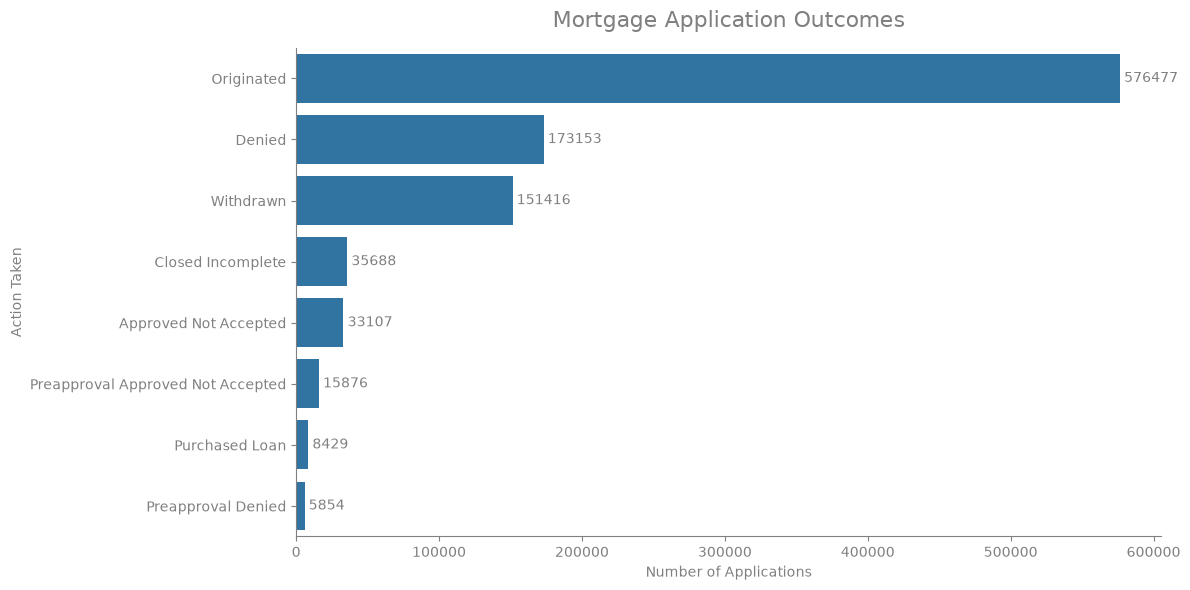

In [171]:
# Initialize figure for target variable distribution
fig, ax = plt.subplots(figsize=(12, 6))

# Generate count plot for action taken
sns.countplot(data=df, y='action_taken_label', order=action_order, ax=ax)

# Set centered title for the chart
ax.set_title('Mortgage Application Outcomes', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Number of Applications', color='grey')
ax.set_ylabel('Action Taken', color='grey')

# Annotate bars with frequency labels for better readability
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine the visual interface by lightening spines and ticks to grey
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(axis='both', colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('action_taken_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

#### Financial Feature Distributions

##### Distribution of Loan Amount

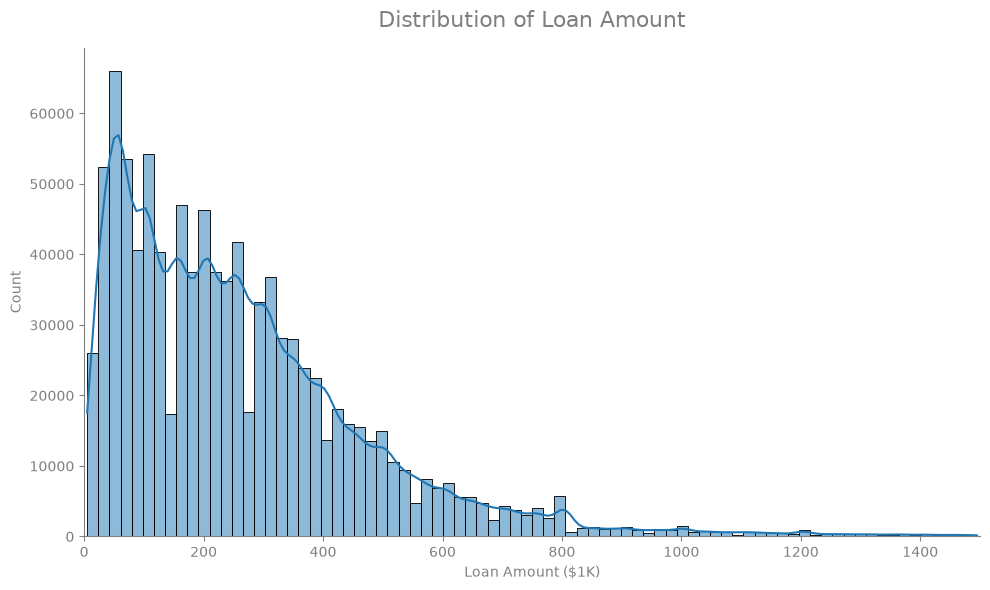

In [172]:
# Initialize figure for loan amount distribution
fig, ax = plt.subplots(figsize=(10, 6))

# Generate histogram and KDE for loan amount
sns.histplot(df[loan_mask]['loan_amount_k'], bins=80, kde=True, ax=ax)

# Set centered title for the chart
ax.set_title('Distribution of Loan Amount', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Loan Amount ($1K)', color='grey')
ax.set_ylabel('Count', color='grey')
ax.set_xlim(0, 1500)

# Refine the visual interface by lightening spines and ticks to grey
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(axis='both', colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('loan_amount_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show histogram plot
plt.show()

##### Distribution of Applicant Income

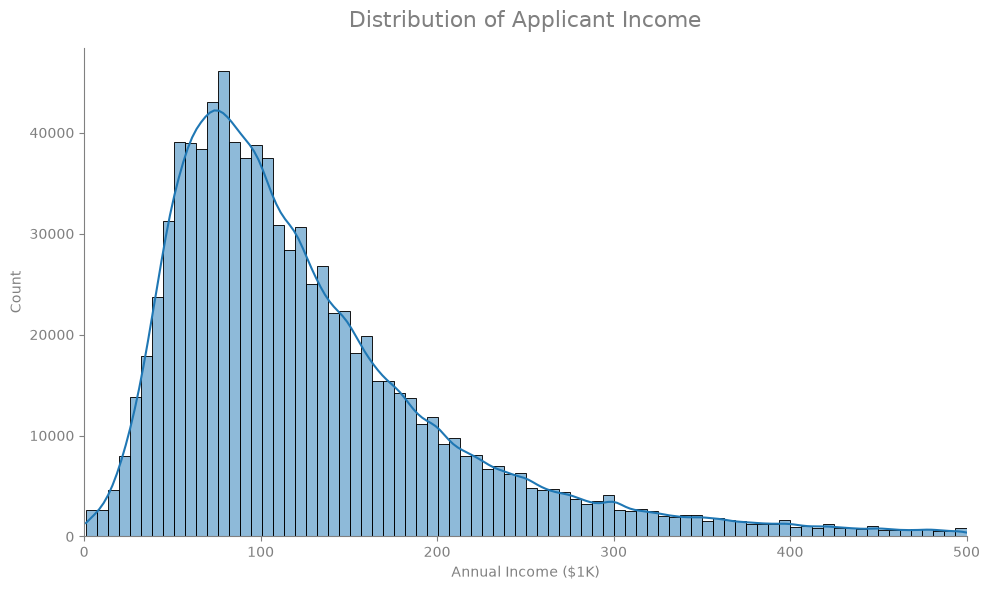

In [173]:
# Initialize figure for applicant income distribution
fig, ax = plt.subplots(figsize=(10, 6))

# Generate histogram and KDE for applicant income
sns.histplot(df[income_mask]['income_k'], bins=80, kde=True, ax=ax)

# Set centered title for the chart
ax.set_title('Distribution of Applicant Income', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Annual Income ($1K)', color='grey')
ax.set_ylabel('Count', color='grey')
ax.set_xlim(0, 500)

# Refine the visual interface by lightening spines and ticks to grey
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(axis='both', colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('applicant_income_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show histogram plot
plt.show()

##### Distribution of Property Value

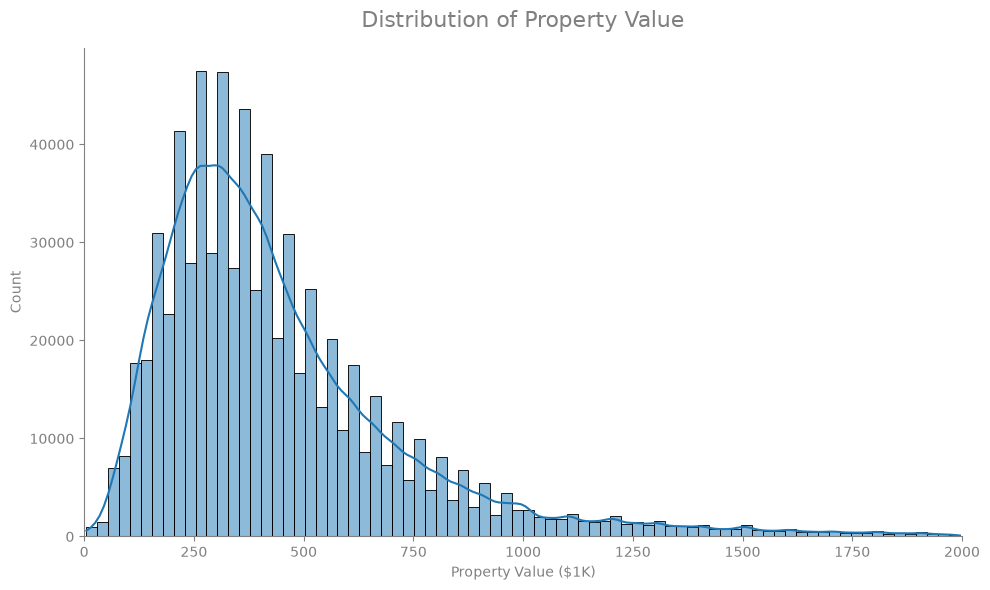

In [174]:
# Initialize figure for property value distribution
fig, ax = plt.subplots(figsize=(10, 6))

# Generate histogram and KDE for property value
sns.histplot(df[property_mask]['property_value_k'], bins=80, kde=True, ax=ax)

# Set centered title for the chart
ax.set_title('Distribution of Property Value', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Property Value ($1K)', color='grey')
ax.set_ylabel('Count', color='grey')
ax.set_xlim(0, 2000)

# Refine the visual interface by lightening spines and ticks to grey
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(axis='both', colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('property_value_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show histogram plot
plt.show()

##### Distribution of Interest Rate

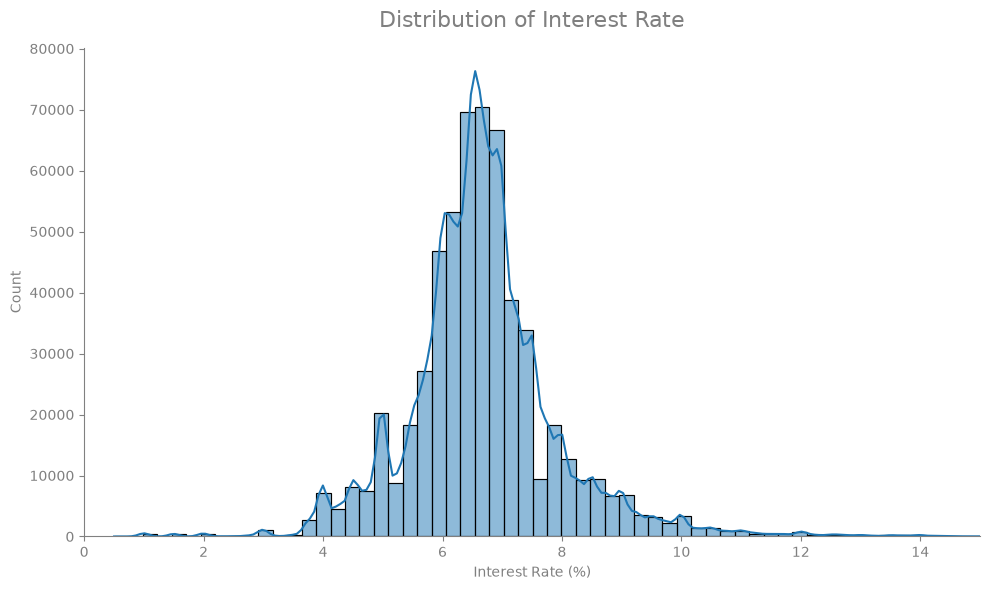

In [175]:
# Initialize figure for interest rate distribution
fig, ax = plt.subplots(figsize=(10, 6))

# Generate histogram and KDE for interest rate
sns.histplot(df[rate_mask]['interest_rate'], bins=60, kde=True, ax=ax)

# Set centered title for the chart
ax.set_title('Distribution of Interest Rate', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Interest Rate (%)', color='grey')
ax.set_ylabel('Count', color='grey')
ax.set_xlim(0, 15)

# Refine the visual interface by lightening spines and ticks to grey
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(axis='both', colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('interest_rate_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show histogram plot
plt.show()

#### Loan Characteristics Count

##### Count of Applications by Loan Purpose

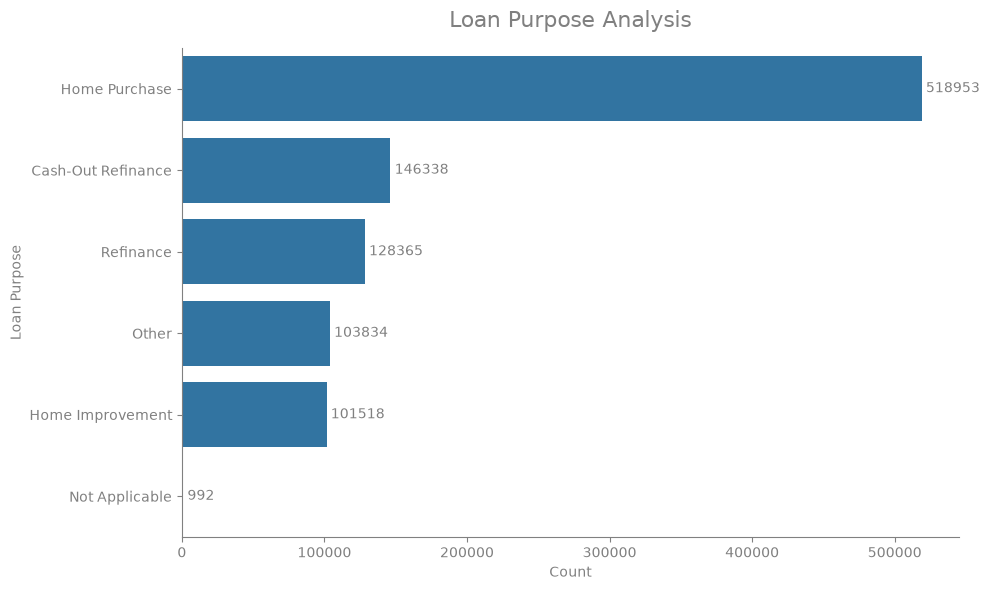

In [176]:
# Initialize figure for loan purpose
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for loan purpose
sns.countplot(data=df, y='loan_purpose_label', order=purpose_order, ax=ax)

# Set centered title for the chart
ax.set_title('Loan Purpose Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Count', color='grey')
ax.set_ylabel('Loan Purpose', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('loan_purpose_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Count of Applications by Loan Type

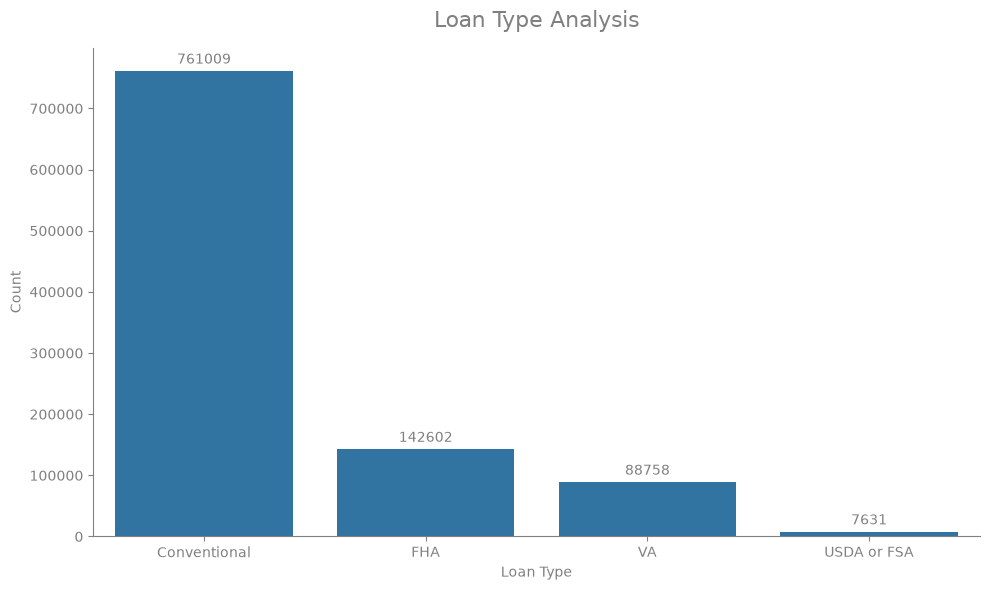

In [177]:
# Initialize figure for loan type
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for loan type
sns.countplot(data=df, x='loan_type_label', order=type_order, ax=ax)

# Set centered title for the chart
ax.set_title('Loan Type Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Loan Type', color='grey')
ax.set_ylabel('Count', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('loan_type_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Count of Applications by Occupancy Type

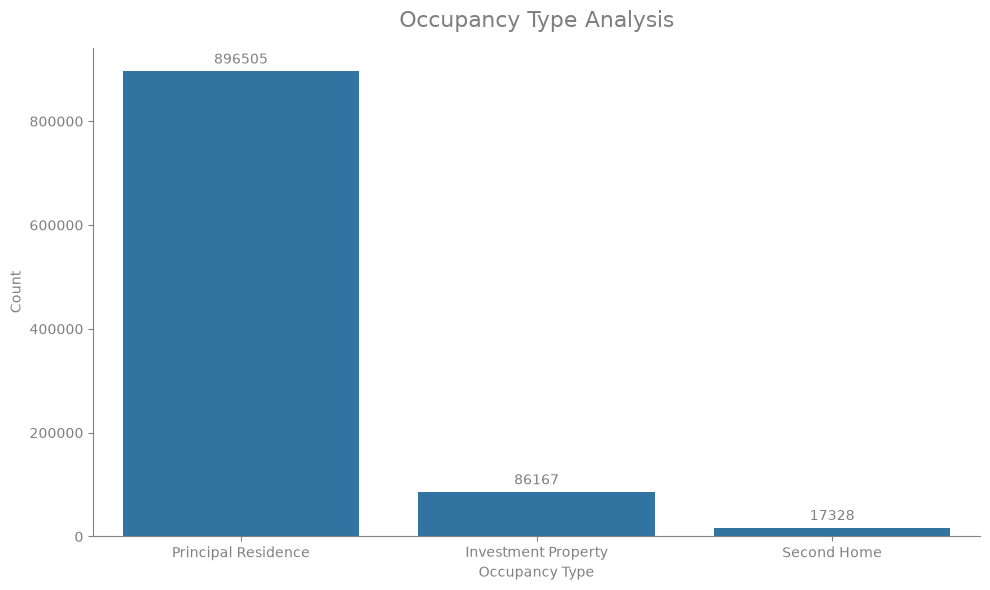

In [178]:
# Initialize figure for occupancy type
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for occupancy type
sns.countplot(data=df, x='occupancy_type_label', order=occupancy_order, ax=ax)

# Set centered title for the chart
ax.set_title('Occupancy Type Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Occupancy Type', color='grey')
ax.set_ylabel('Count', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('occupancy_type_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Count of Applications by Lien Status

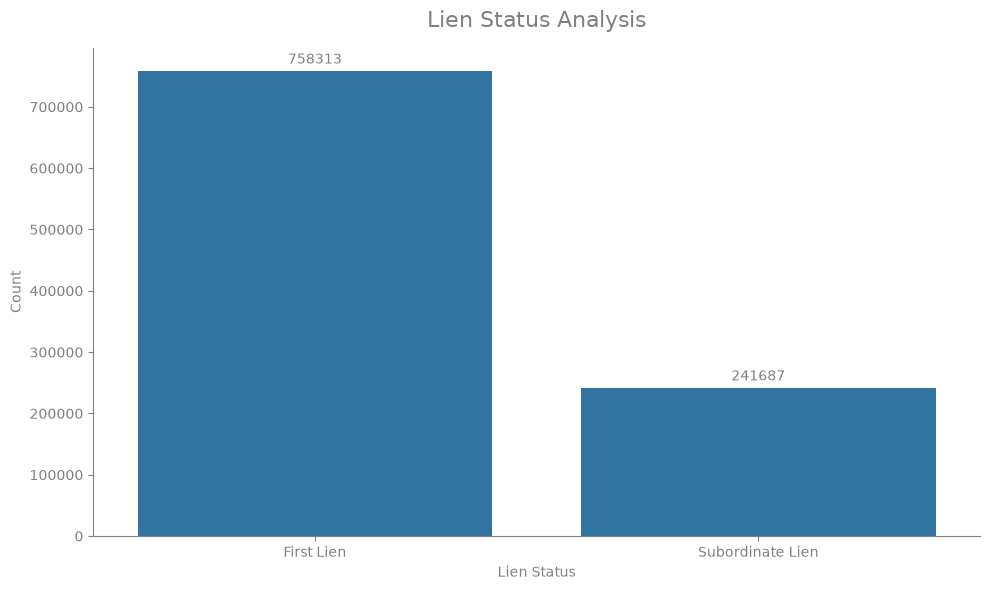

In [179]:
# Initialize figure for lien status
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for lien status
sns.countplot(data=df, x='lien_status_label', ax=ax)

# Set centered title for the chart
ax.set_title('Lien Status Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Lien Status', color='grey')
ax.set_ylabel('Count', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('lien_status_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

#### Applicant Demographics Count

##### Applications by Derived Race

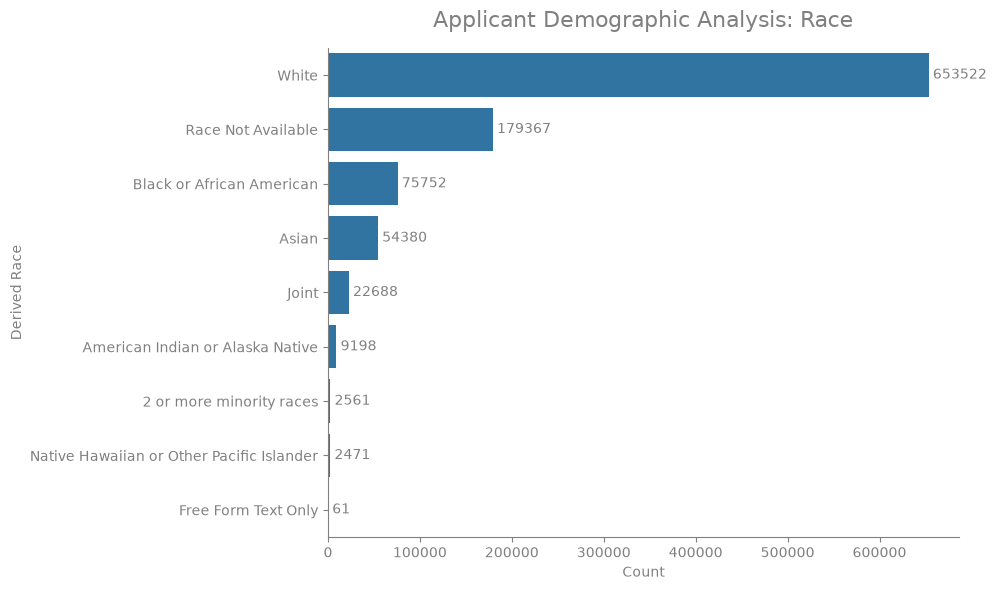

In [180]:
# Initialize figure for applicant race
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for applicant race
sns.countplot(data=df, y='derived_race', order=race_order, ax=ax)

# Set centered title for the chart
ax.set_title('Applicant Demographic Analysis: Race', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Count', color='grey')
ax.set_ylabel('Derived Race', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('applicant_race_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Applications by Derived Ethnicity

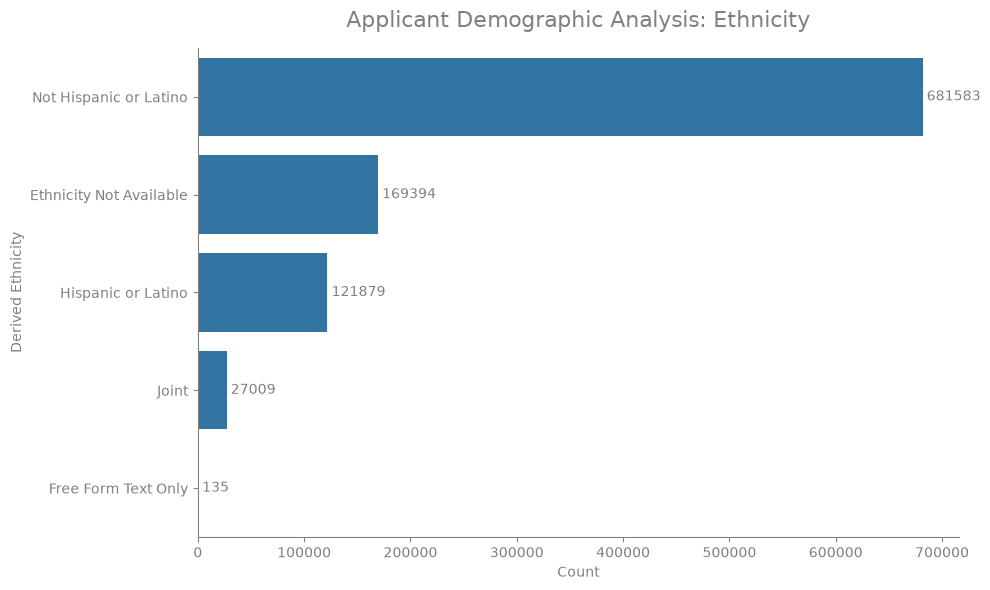

In [181]:
# Initialize figure for applicant ethnicity
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for applicant ethnicity
sns.countplot(data=df, y='derived_ethnicity', order=ethnicity_order, ax=ax)

# Set centered title for the chart
ax.set_title('Applicant Demographic Analysis: Ethnicity', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Count', color='grey')
ax.set_ylabel('Derived Ethnicity', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('applicant_ethnicity_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Applications by Derived Sex

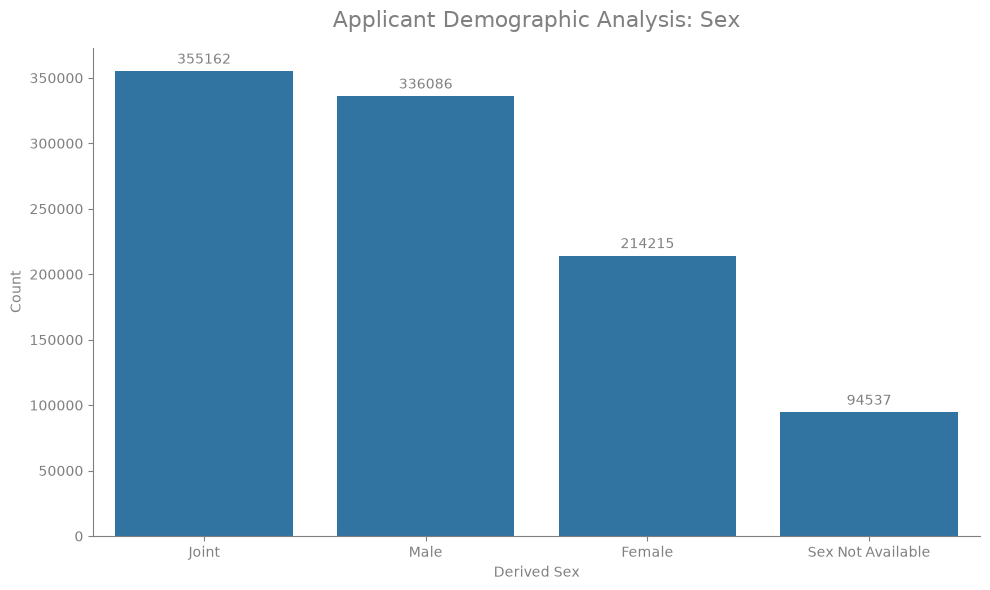

In [182]:
# Initialize figure for applicant sex
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for applicant sex
sns.countplot(data=df, x='derived_sex', order=sex_order, ax=ax)

# Set centered title for the chart
ax.set_title('Applicant Demographic Analysis: Sex', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Derived Sex', color='grey')
ax.set_ylabel('Count', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('applicant_sex_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Applications by Applicant Age Group

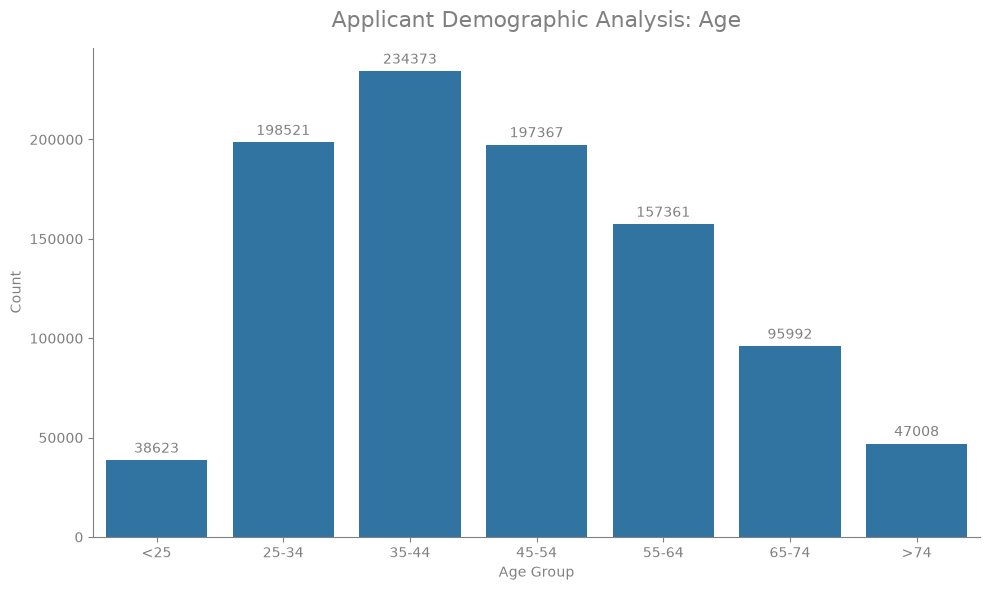

In [183]:
# Initialize figure for applicant age
fig, ax = plt.subplots(figsize=(10, 6))

# Generate count plot for applicant age using existing string categories
sns.countplot(data=df_valid_age, x='applicant_age', order=age_order, ax=ax)

# Set centered title for the chart
ax.set_title('Applicant Demographic Analysis: Age', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Age Group', color='grey')
ax.set_ylabel('Count', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Adjust layout to prevent overlapping and display the plot
plt.tight_layout()

# Save graph
plt.savefig('applicant_age_dist_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

### Bivariate Analysis

#### Income and Loan Amount by Application Outcome

##### Applicant Income Across Application Outcomes

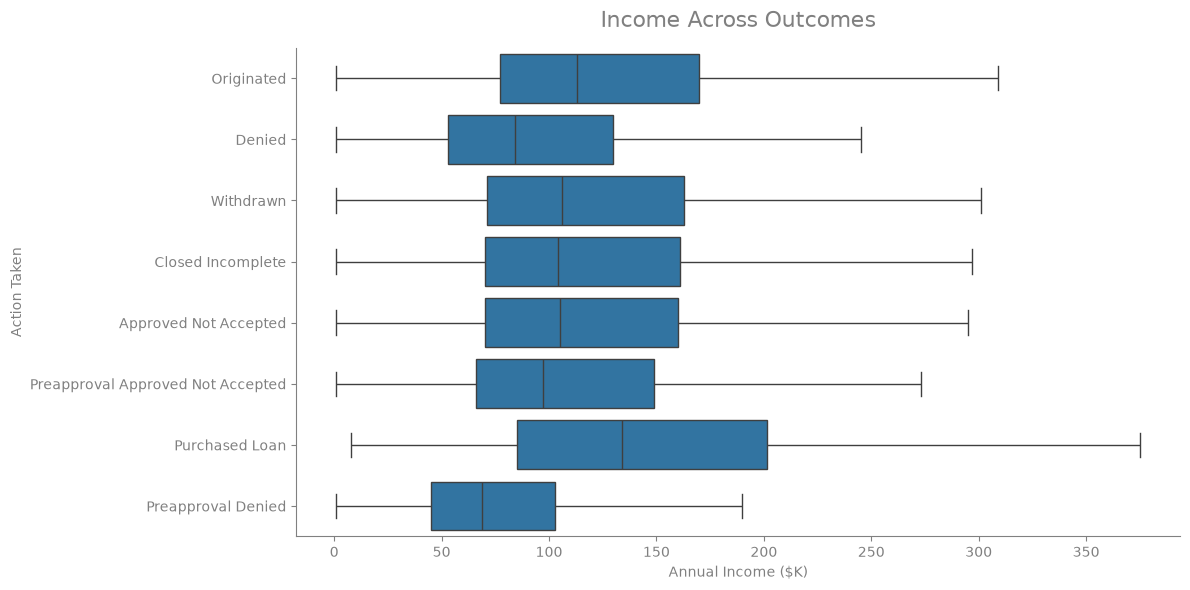

In [184]:
# Initialize figure for applicant income across outcomes
fig, ax = plt.subplots(figsize=(12, 6))

# Generate boxplot for applicant income by action taken
sns.boxplot(data=df[income_mask], x='income_k', y='action_taken_label', order=action_order, 
            ax=ax, showfliers=False)

# Set centered title for the chart
ax.set_title('Income Across Outcomes', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Annual Income ($K)', color='grey')
ax.set_ylabel('Action Taken', color='grey')

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('income_by_outcome_hmda.png', dpi=300, bbox_inches='tight')

# Show boxplot
plt.show()

##### Loan Amount Across Application Outcomes

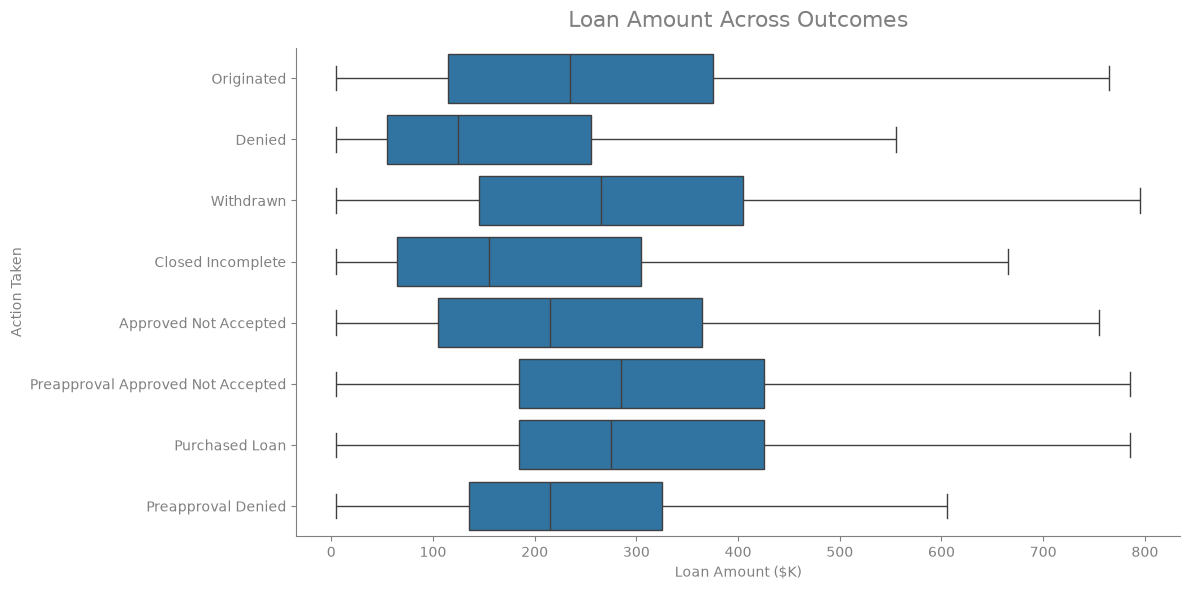

In [185]:
# Initialize figure for loan amount across outcomes
fig, ax = plt.subplots(figsize=(12, 6))

# Generate boxplot for loan amount by action taken
sns.boxplot(data=df[loan_mask], x='loan_amount_k', y='action_taken_label', order=action_order, 
            ax=ax, showfliers=False)

# Set centered title for the chart
ax.set_title('Loan Amount Across Outcomes', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Loan Amount ($K)', color='grey')
ax.set_ylabel('Action Taken', color='grey')

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('loan_amount_by_outcome_hmda.png', dpi=300, bbox_inches='tight')

# Show boxplot
plt.show()

#### Debt-to-Income Ratio and Primary Denial Reasons

##### Distribution of Debt-to-Income (DTI) Ratio

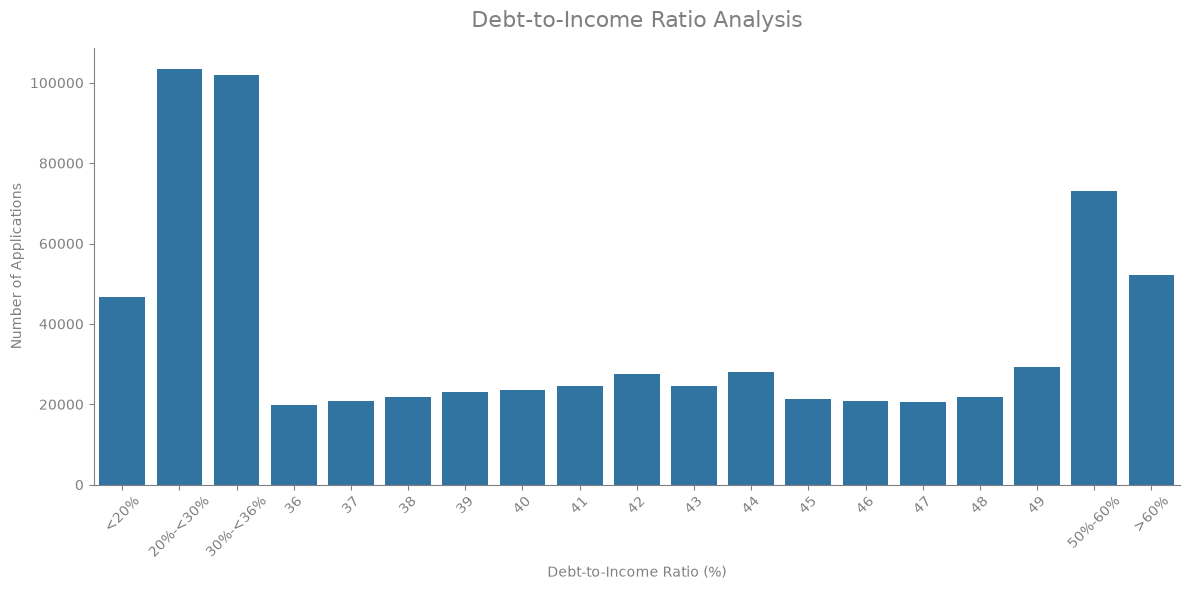

In [186]:
# Initialize figure for debt-to-income ratio
fig, ax = plt.subplots(figsize=(12, 6))

# Count of applications by existing Debt-to-Income Ratio string categories
sns.countplot(data=df, x='debt_to_income_ratio', order=dti_order, ax=ax)

# Set centered title for the chart
ax.set_title('Debt-to-Income Ratio Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Debt-to-Income Ratio (%)', color='grey')
ax.set_ylabel('Number of Applications', color='grey')
ax.tick_params(axis='x', rotation=45)

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('dti_distribution_hmda.png', dpi=300, bbox_inches='tight')

# Show plot
plt.show()

##### Primary Reasons for Denial Among Denied Applications

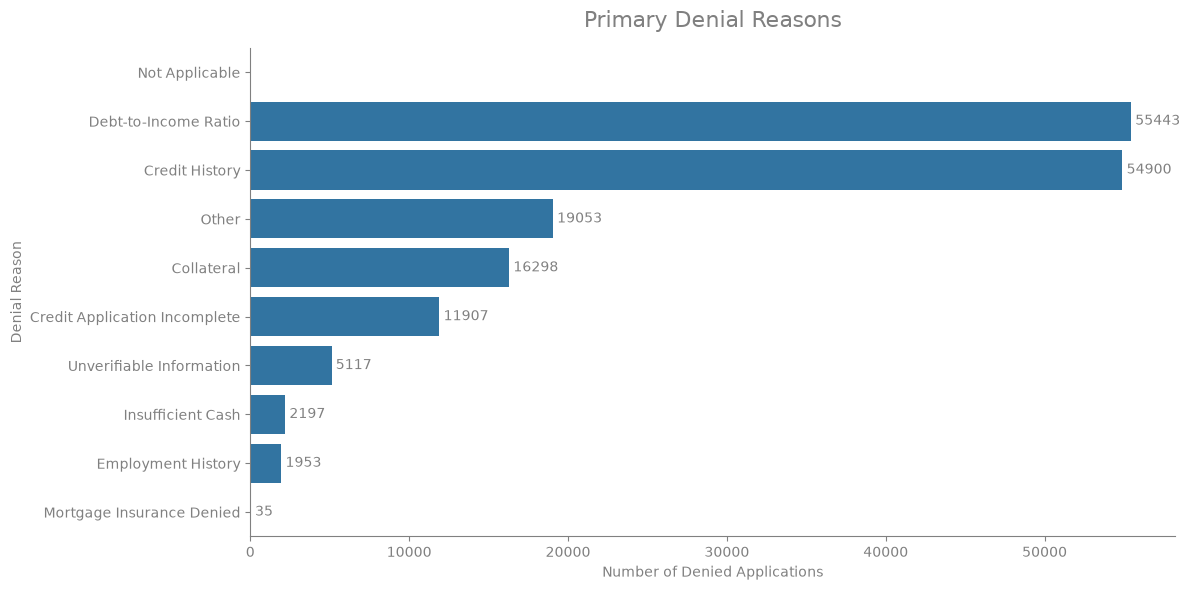

In [187]:
# Initialize figure for denial reasons
fig, ax = plt.subplots(figsize=(12, 6))

# Primary reasons for denied applications
sns.countplot(data=df_denied, y='denial_reason_label', order=denial_order, ax=ax)

# Set centered title for the chart
ax.set_title('Primary Denial Reasons', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Number of Denied Applications', color='grey')
ax.set_ylabel('Denial Reason', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('denial_reasons_hmda.png', dpi=300, bbox_inches='tight')

# Show plot
plt.show()

#### State Volume and Lender Variety Distribution

##### Total Mortgage Applications by Top 15 States

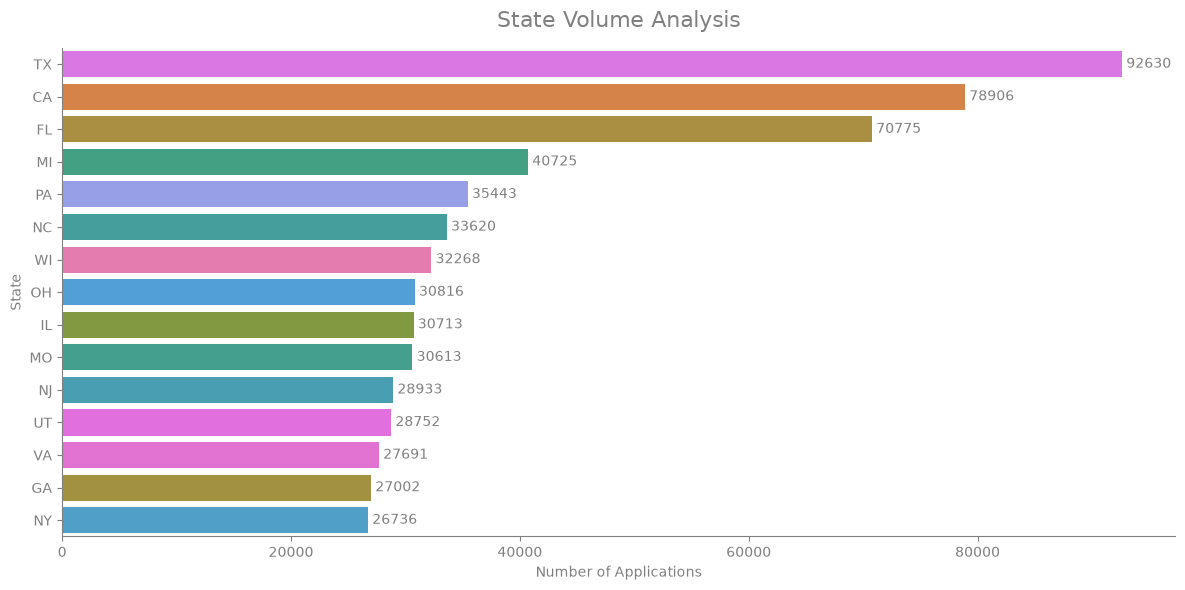

In [188]:
# Initialize figure for top 15 states volume
fig, ax = plt.subplots(figsize=(12, 6))

# Total Application Count by Top 15 States
sns.countplot(data=df_top_states, y='state_code', order=state_order, 
              ax=ax, hue='state_code', dodge=False, legend=False)

# Set centered title for the chart
ax.set_title('State Volume Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Number of Applications', color='grey')
ax.set_ylabel('State', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('state_volume_hmda.png', dpi=300, bbox_inches='tight')

# Show barplot
plt.show()

##### Market Competition: Number of Unique Lenders per State

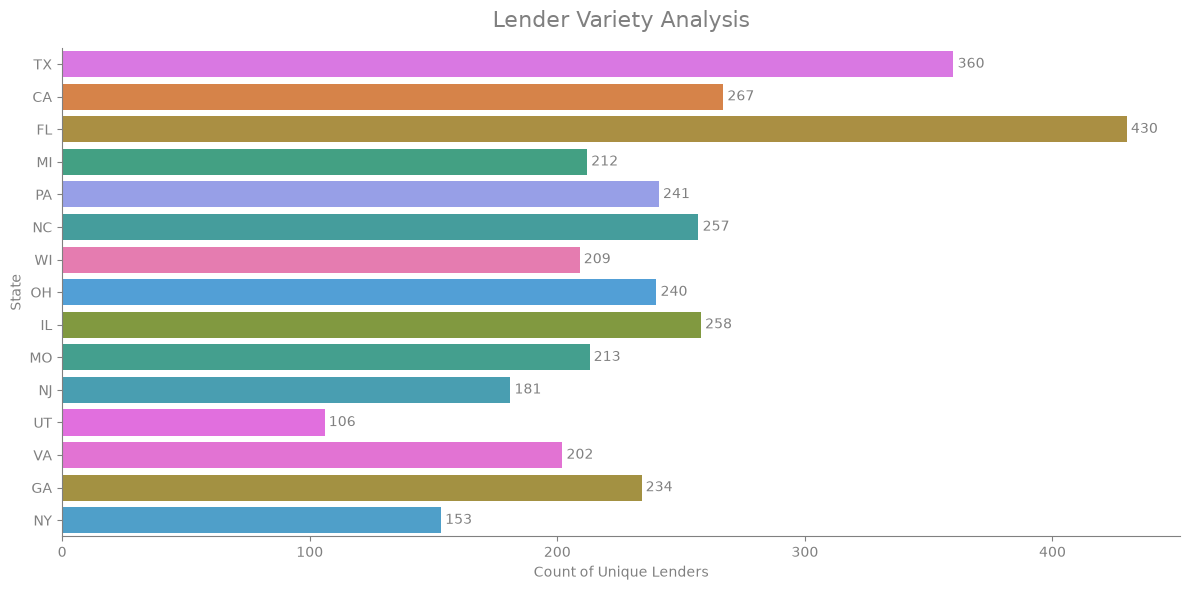

In [189]:
# Initialize figure for unique lenders per state
fig, ax = plt.subplots(figsize=(12, 6))

# Unique Lenders (LEI) per State using the same state order
unique_lenders = df_top_states.groupby('state_code', observed=False)['lei'].nunique()

sns.barplot(x=unique_lenders.values, y=unique_lenders.index, order=state_order,
            ax=ax, hue=unique_lenders.index, dodge=False, legend=False)

# Set centered title for the chart
ax.set_title('Lender Variety Analysis', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Count of Unique Lenders', color='grey')
ax.set_ylabel('State', color='grey')

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, color='grey')

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('unique_lenders_per_state_hmda.png', dpi=300, bbox_inches='tight')

# Show barplot
plt.show()

### Multivariate Analysis

#### Loan Purpose and Loan Type by Application Outcome

##### Application Outcomes Across Loan Purposes

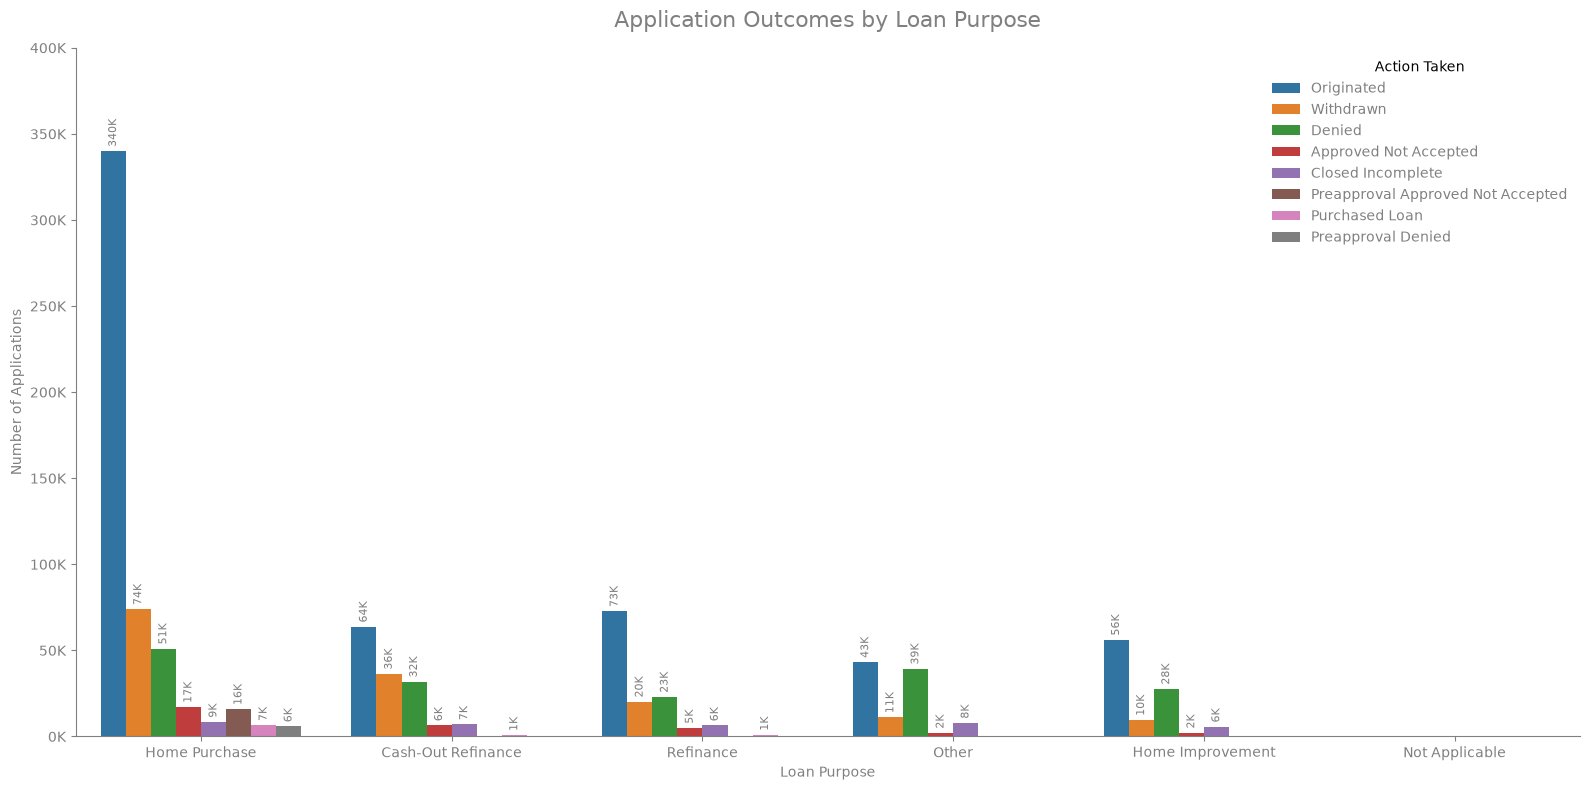

In [190]:
# Initialize figure for loan purpose across outcomes
fig, ax = plt.subplots(figsize=(16, 8))

# Generate vertical count plot for loan purpose split by action taken
sns.countplot(data=df, x='loan_purpose_label', order=purpose_order, hue='action_taken_label', ax=ax)

# Set centered title for the chart
ax.set_title('Application Outcomes by Loan Purpose', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Loan Purpose', color='grey')
ax.set_ylabel('Number of Applications', color='grey')

# Format Y-axis tick values manually in thousands (K)
ticks = ax.get_yticks()
tick_labels = []
for tick in ticks:
    thousands_value = int(tick / 1000)
    label = str(thousands_value) + "K"
    tick_labels.append(label)
ax.set_yticks(ticks)
ax.set_yticklabels(tick_labels)

ax.legend(title='Action Taken', frameon=False, labelcolor='grey')

# Add numbers on each bar rounded to K
for container in ax.containers:
    labels = []
    for val in container.datavalues:
        if val >= 500:
            k_val = round(val / 1000)
            labels.append(str(k_val) + "K")
        else:
            labels.append('')
            
    ax.bar_label(container, labels=labels, padding=3, color='grey', fontsize=8, rotation=90)


# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('purpose_by_outcome_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

##### Application Outcomes Across Loan Types

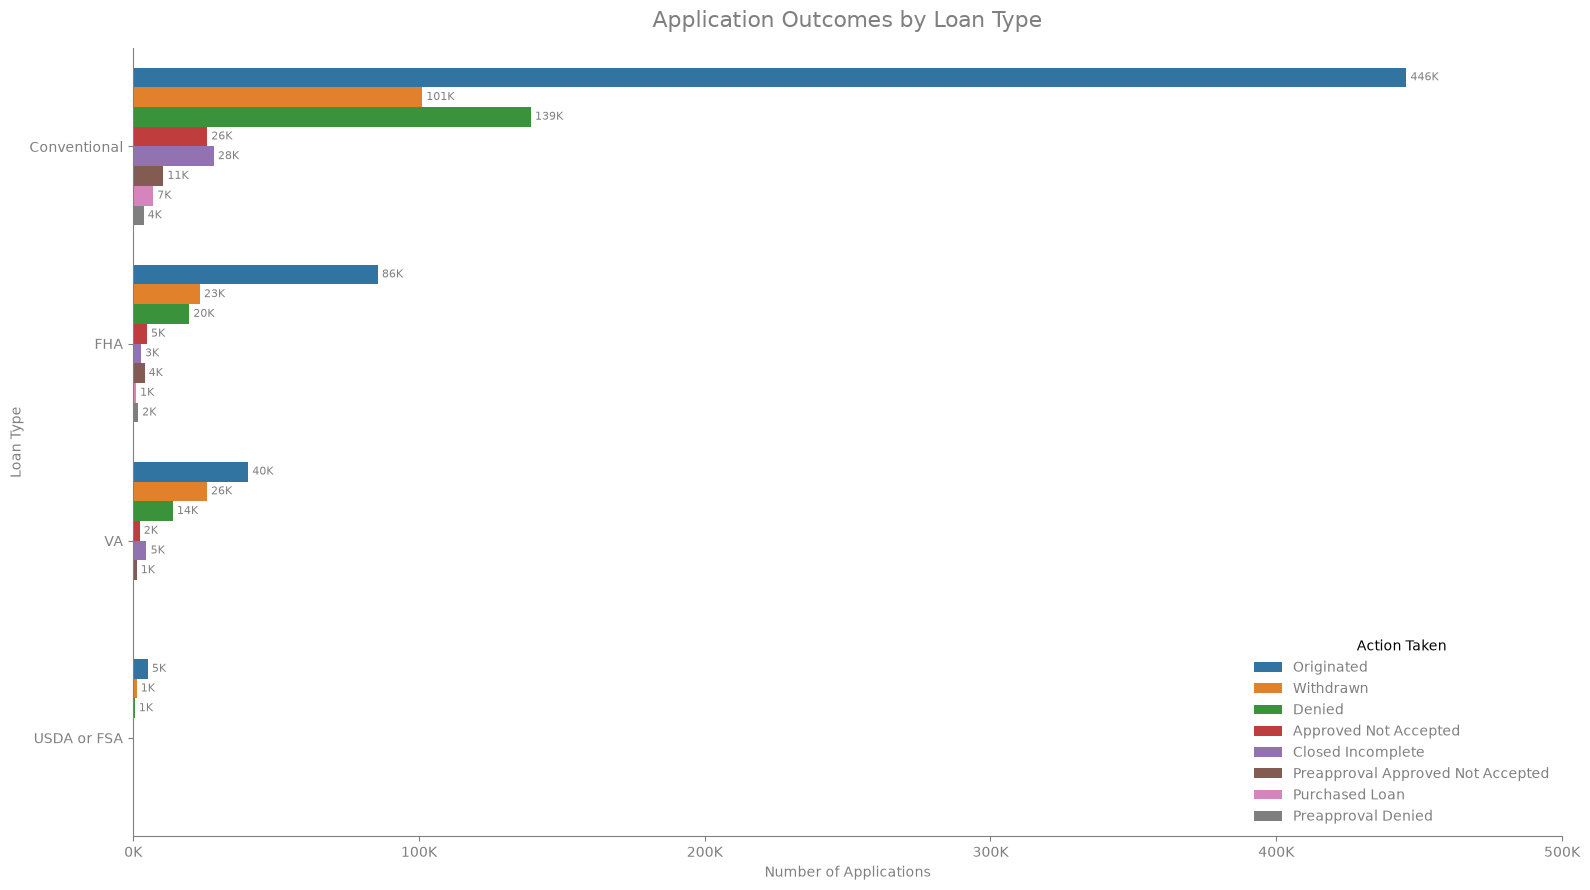

In [191]:
# Initialize figure for loan type across outcomes
fig, ax = plt.subplots(figsize=(16, 9))

# Generate horizontal count plot for loan type split by action taken
sns.countplot(data=df, y='loan_type_label', order=type_order, hue='action_taken_label', ax=ax)

# Set centered title for the chart
ax.set_title('Application Outcomes by Loan Type', loc='center', color='grey', fontsize=16, pad=15)
ax.set_xlabel('Number of Applications', color='grey')
ax.set_ylabel('Loan Type', color='grey')

# Format X-axis tick values in thousands (K)
ticks = ax.get_xticks()
tick_labels = []

for tick in ticks:
    thousands_value = int(tick / 1000)
    label = str(thousands_value) + "K"
    tick_labels.append(label)

ax.set_xticks(ticks)
ax.set_xticklabels(tick_labels)

ax.legend(title='Action Taken', frameon=False, labelcolor='grey')

# Add numbers on each bar rounded to K
for container in ax.containers:
    labels = []
    for val in container.datavalues:
        if val >= 500:
            k_val = round(val / 1000)
            labels.append(str(k_val) + "K")
        else:
            labels.append('')
            
    ax.bar_label(container, labels=labels, padding=3, color='grey', fontsize=8)

# Refine the visual interface by stripping clutter and applying grey tones
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('grey')
ax.spines['bottom'].set_color('grey')
ax.tick_params(colors='grey')

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('type_by_outcome_hmda.png', dpi=300, bbox_inches='tight')

# Show countplot
plt.show()

#### Correlation Matrix

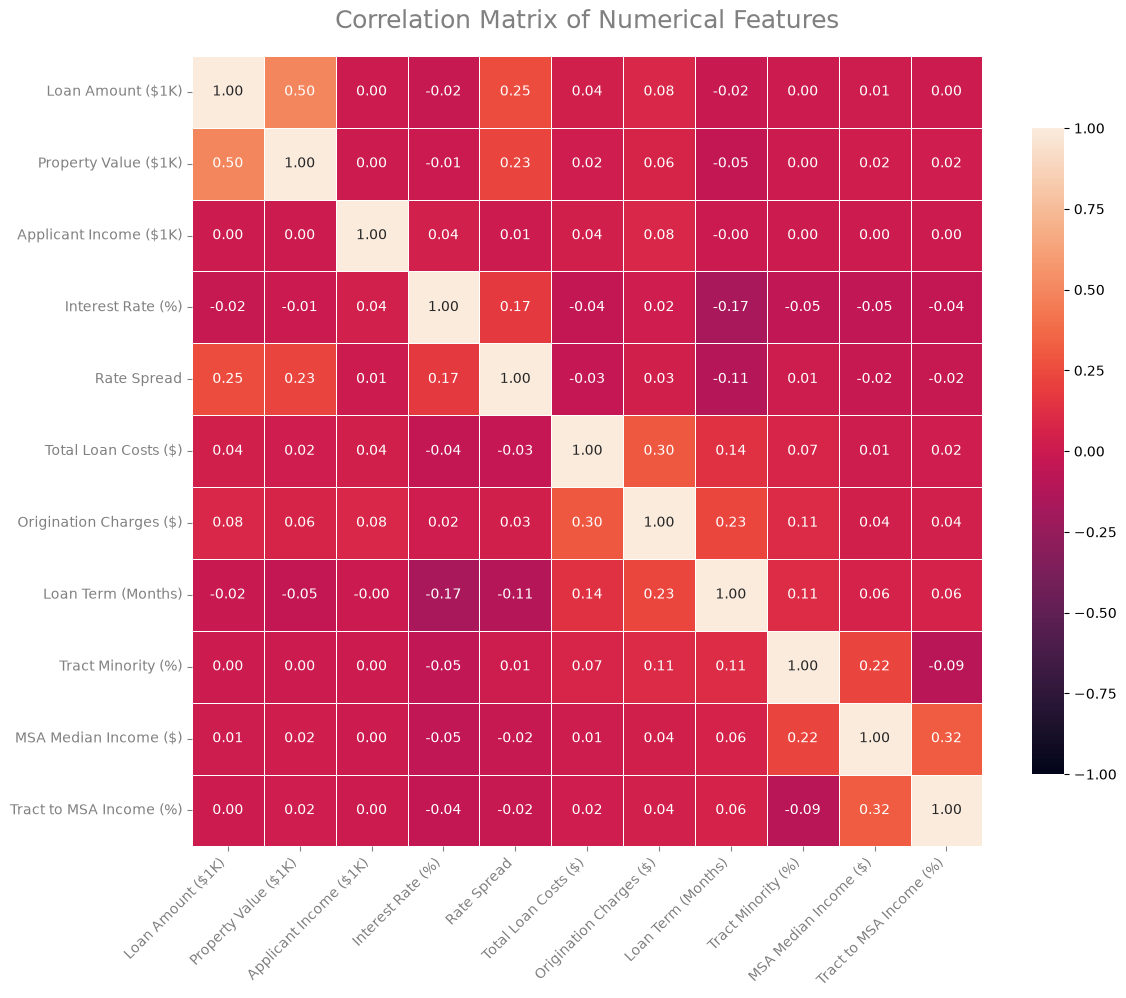

In [192]:
# Set figure size for the correlation heatmap using the object-oriented interface
fig, ax = plt.subplots(figsize=(12, 10))

# Calculate the Pearson correlation coefficients for the selected numerical features
corr_hmda = df[corr_cols].corr()

# Generate heatmap with clean text labels (no underscores)
sns.heatmap(
    corr_hmda, 
    annot=True, 
    fmt='.2f', 
    vmin=-1, 
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    xticklabels=corr_clean_labels,
    yticklabels=corr_clean_labels,
    ax=ax
)

# Set centered title for the chart
ax.set_title('Correlation Matrix of Numerical Features', loc='center', color='grey', fontsize=18, pad=20)

# Refine axis ticks and labels
ax.tick_params(colors='grey')

# X-axis: Rotating 45 degrees for readability
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', color='grey')

# Y-axis: Horizontal alignment for readability
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, va='center', color='grey')

# Remove the outer spines
for spine in ax.spines.values():
    spine.set_visible(False)

# Optimize layout
plt.tight_layout()

# Save graph
plt.savefig('heatmap_hmda.png', dpi=300, bbox_inches='tight')

# Show heatmap
plt.show()